# 6) Barocaloric Potential

This notebook illustrates how results already stored in SCO ATLAS can be recombined to screen for molecular features relevant to the barocaloric effect (BCE). The procedure is intentionally simple: combine the total molecular entropy change with a molecular-volume expansion descriptor, normalize both by molecular mass, and rank the systems.

The resulting ranking is a **molecular triage list**, not a prediction of experimental BCE performance. Crystal packing, counterions, lattice phonons, hysteresis, reversibility, and pressure-dependent phase behaviour are outside the present gas-phase layer of the ATLAS.

In [1]:
import os
import sys

import scope
import scope_sco

sys.path.insert(0, os.path.abspath('..'))
from atlas_functions import *

In [2]:
data_path     = "/Users/sergivela/Documents/SCOPE/Database_SCO/Data/"                    # Update with your path
analysis_path = "/Users/sergivela/Documents/SCOPE/Database_SCO/Analysis/"                # Update with your path
env_path      = "/Users/sergivela/Documents/SCOPE/Database_SCO/Data/scope_env_atlas.npy" # Update with your path

save_figures = True
if save_figures:
    figures_path = "/Users/sergivela/Documents/SCOPE/Database_SCO/Manuscript/figures/"    # Update with your path
else:
    figures_path = None

data_path     = os.path.abspath(os.path.expanduser(data_path)) + os.sep
analysis_path = os.path.abspath(os.path.expanduser(analysis_path)) + os.sep
env_path      = os.path.abspath(os.path.expanduser(env_path))
outputs_path  = analysis_path + "Outputs/"

expected_scope_version = "0.9.6"
installed_scope_version = getattr(scope, "__version__", None)
if installed_scope_version != expected_scope_version:
    raise RuntimeError(
        f"This analysis requires SCOPE {expected_scope_version}; "
        f"the active environment provides {installed_scope_version!r}."
    )

required_paths = [data_path + "2-Systems/", outputs_path]
missing_paths = [path for path in required_paths if not os.path.isdir(path)]
if missing_paths:
    raise FileNotFoundError(f"Missing required SCO ATLAS directories: {missing_paths}")
if not os.path.isfile(env_path):
    raise FileNotFoundError(f"SCOPE environment file not found: {env_path}")
if figures_path is not None:
    os.makedirs(figures_path, exist_ok=True)

env = scope.load_binary(env_path)
thermodynamic_path = outputs_path + "unique_thermodynamic_data.csv"
structural_path    = outputs_path + "unique_structural_data.csv"
unique_path        = outputs_path + "unique_systems.csv"
screening_path     = outputs_path + "bce_vibrational_screening_data.csv"

print(f"SCOPE version:     {installed_scope_version}")
print(f"Data directory:    {data_path}")
print(f"Analysis outputs:  {outputs_path}")
print(f"Manuscript figures: {figures_path}")

SCOPE version:     0.9.6
Data directory:    /Users/sergivela/Documents/SCOPE/Database_SCO/Data/
Analysis outputs:  /Users/sergivela/Documents/SCOPE/Database_SCO/Analysis/Outputs/
Manuscript figures: /Users/sergivela/Documents/SCOPE/Database_SCO/Manuscript/figures/


## 1. Molecular Screening Strategy

For every TMC, the ATLAS already contains the vibrational and electronic entropy terms at 298.15 K and the convex-hull (CH) volumes of the optimized HS and LS minima. We combine them as

$$\Delta S_{\mathrm{tot}}^{298}=\Delta S_{\mathrm{vib}}^{298}+\Delta S_{\mathrm{elec}},$$

where $\Delta S_{\mathrm{elec}}=R\ln(5)$ for the Fe(II) LS singlet to HS quintet transition. The molecular expansion is

$$\Delta V_{\mathrm{CH}}=V_{\mathrm{CH}}^{\mathrm{HS}}-V_{\mathrm{CH}}^{\mathrm{LS}}.$$

Both quantities are converted to mass-specific descriptors. The exploratory score

$$\Pi_{\mathrm{BCE}}=\Delta S_{\mathrm{tot,m}}^{298}\max(\Delta V_{\mathrm{CH,m}},0)$$

prioritizes molecules that combine a large intrinsic entropy density with a positive molecular expansion. Negative CH changes are retained in the exported data, but contribute zero to the score.

In [3]:
temperature = 298.15
denticities_to_compare = ['1', '2', '3', '6']
overwrite = False

## 2. Build The Screening Table

This step joins the thermodynamic and structural output tables by refcode. The associated SCOPE `System` objects are opened only to obtain molecular mass and charge. No quantum-chemical result is recomputed.

Set `overwrite = True` above to rebuild the BCE table explicitly. It is rebuilt automatically if its refcodes do not match the current `unique_systems.csv`.

In [4]:
thermodynamic_rows = read_csv(thermodynamic_path)
structural_rows    = read_csv(structural_path)
unique_rows        = read_csv(unique_path)
expected_refcodes  = {base_refcode(row['refcode']) for row in unique_rows}

rebuild = overwrite or not os.path.isfile(screening_path)
if not rebuild:
    screening_rows = read_bce_screening_rows(screening_path)
    cached_refcodes = {row['refcode'] for row in screening_rows}
    rebuild = cached_refcodes != expected_refcodes
    if rebuild:
        print('The cached BCE table does not match the current unique systems; rebuilding it.')

if rebuild:
    unique_systems = []
    for row in unique_rows:
        system = scope.load_binary(resolve_system_path(row['path'], data_path))
        system.set_paths_from_environment(env)
        unique_systems.append(system)

    screening_rows, failures = build_bce_screening_rows(
        unique_systems,
        thermodynamic_rows,
        structural_rows,
        temperature=temperature,
    )
    write_bce_screening_rows(screening_path, screening_rows)
    print(f'Wrote {len(screening_rows)} entries to {screening_path}')
    print(f'Failed entries: {len(failures)}')
    if failures:
        display_data_table(failures, ['refcode', 'reason'], maximum_rows=10)
else:
    failures = []
    print(f'Loaded {len(screening_rows)} entries from {screening_path}')

Loaded 602 entries from /Users/sergivela/Documents/SCOPE/Database_SCO/Analysis/Outputs/bce_vibrational_screening_data.csv


## 3. Query And Rank Candidates

The screening is deliberately expressed as ordinary filtering and sorting of CSV rows. Optional composition, charge, and $T_{1/2}$ filters can be activated below. Leaving them as `None` retains all available systems.

In [5]:
composition_filter = None  # None, 'homoleptic', or 'heteroleptic'
charge_filter      = None  # None, 'neutral', or 'charged'
t12_window         = None  # For example, (250, 350)
minimum_entropy    = None  # J kg-1 K-1
minimum_volume     = 0.0   # cm3 g-1
number_to_show     = 40

In [6]:
candidate_rows = [
    row for row in screening_rows
    if row['dStotal_mass_JkgK'] is not None
    and row['dV_hull_cm3g'] is not None
    and row['dV_hull_cm3g'] > minimum_volume
]

if composition_filter == 'homoleptic':
    candidate_rows = [row for row in candidate_rows if row['homoleptic']]
elif composition_filter == 'heteroleptic':
    candidate_rows = [row for row in candidate_rows if not row['homoleptic']]

if charge_filter == 'neutral':
    candidate_rows = [row for row in candidate_rows if not row['charged']]
elif charge_filter == 'charged':
    candidate_rows = [row for row in candidate_rows if row['charged']]

if t12_window is not None:
    candidate_rows = [
        row for row in candidate_rows
        if row['T12_K'] is not None and t12_window[0] <= row['T12_K'] <= t12_window[1]
    ]
if minimum_entropy is not None:
    candidate_rows = [row for row in candidate_rows if row['dStotal_mass_JkgK'] >= minimum_entropy]

candidate_rows.sort(
    key=lambda row: (row['BCE_metric_mass'], row['dStotal_mass_JkgK'], row['dV_hull_cm3g']),
    reverse=True,
)

screening_columns = [
    'refcode', 'denticity', 'homoleptic', 'charged', 'molecular_weight_gmol',
    'dStotal_mass_JkgK', 'dV_hull_cm3g', 'BCE_metric_mass', 'T12_K',
]
screening_labels = {
    'molecular_weight_gmol': 'MW [g mol-1]',
    'dStotal_mass_JkgK': 'dStotal(298 K) [J kg-1 K-1]',
    'dV_hull_cm3g': 'dVCH [cm3 g-1]',
    'BCE_metric_mass': 'Pi_BCE',
    'T12_K': 'T1/2 [K]',
}

print(f'{len(candidate_rows)} systems satisfy the selected filters.')
display_data_table(
    candidate_rows, screening_columns, labels=screening_labels,
    digits=2, maximum_rows=number_to_show,
)

candidate_table_path = outputs_path + 'BCE_top40_candidates_table.tex'
write_bce_candidates_latex(candidate_table_path, candidate_rows, maximum_rows=number_to_show)
print(f'Wrote {candidate_table_path}')

458 systems satisfy the selected filters.


refcode,denticity,homoleptic,charged,MW [g mol-1],dStotal(298 K) [J kg-1 K-1],dVCH [cm3 g-1],Pi_BCE,T1/2 [K]
RAPXOY,1,True,True,302.15,356.54,0.07,23.80,189.00
JOWGEH,2,True,True,308.19,320.11,0.04,11.31,-
RANCUG,2,True,True,425.30,254.33,0.04,11.23,133.00
DOQRAC,unknown,False,True,350.27,251.16,0.04,11.14,202.00
ADAQUU,unknown,False,False,584.49,124.96,0.08,10.36,166.00
BAKGUR,2,True,True,509.45,203.74,0.05,9.27,-
DEDMAC,unknown,False,False,556.52,178.80,0.05,8.88,63.00
HIPXOW,1,True,True,560.31,202.59,0.04,8.65,104.00
YOYVEQ,unknown,False,True,396.25,194.12,0.04,8.48,451.00
RIYTIC,unknown,False,True,418.30,225.91,0.04,8.37,379.00


Wrote /Users/sergivela/Documents/SCOPE/Database_SCO/Analysis/Outputs/BCE_top40_candidates_table.tex


The essential screening operation is therefore only:

```python
candidate_rows = [
    row for row in screening_rows
    if row['dV_hull_cm3g'] is not None and row['dV_hull_cm3g'] > 0
]
candidate_rows.sort(key=lambda row: row['BCE_metric_mass'], reverse=True)
```

This compact query is suitable for illustrating ATLAS reuse in the manuscript or ESI.

## 4. Molecular BCE Screening Map

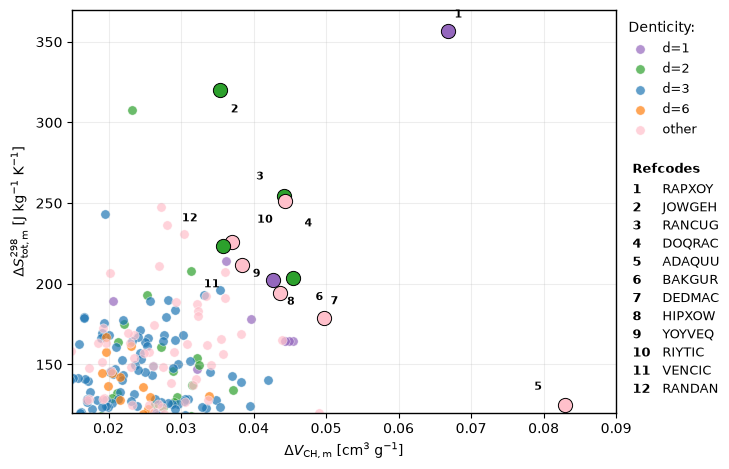

(<Figure size 740x480 with 1 Axes>,
 <Axes: xlabel='$\\Delta V_{\\mathrm{CH,m}}$ [cm$^3$ g$^{-1}$]', ylabel='$\\Delta S_{\\mathrm{tot,m}}^{298}$ [J kg$^{-1}$ K$^{-1}$]'>)

In [7]:
screening_figure_path = None
if figures_path is not None:
    screening_figure_path = figures_path + 'BCE_screening_mass_specific.png'

plot_bce_screening(
    candidate_rows,
    output_path=screening_figure_path,
    denticities=denticities_to_compare,
    number_labels=12,
    x_limits=(0.015, 0.09),
    y_limits=(120, 370),
    label_offsets={
        'RANCUG': (-14, 10), 'DOQRAC': (14, -12),
        'BAKGUR': (16, -10), 'HIPXOW': (10, -12), 'YOYVEQ': (-14, 10),
        'RIYTIC': (18, 12), 'VENCIC': (-16, -10), 'RANDAN': (-18, 16),
    },
)

**Caption.** Molecular BCE screening map using mass-specific gas-phase descriptors. The y-axis is the estimated total entropy change, $\Delta S_{\mathrm{tot,m}}^{298}$, and the x-axis is the convex-hull molecular-volume change, $\Delta V_{\mathrm{CH,m}}$. Numbered labels identify the highest-ranked systems according to $\Pi_{\mathrm{BCE}}$. The displayed upper-right region emphasizes candidates combining both favourable descriptors.

## 5. GAPSIA As An Experimental Reference

GAPSIA is the CSD refcode associated with the landmark $[\mathrm{FeL}_2][\mathrm{BF}_4]_2$ barocaloric material. SCO ATLAS contains the non-deuterated isolated SCO cation, whereas the experimental mass-specific quantities refer to the partially deuterated full salt. The comparison below calibrates the molecular descriptors; it is not intended as a direct prediction of the crystal response.

In [8]:
gapsia = next(row for row in screening_rows if row['refcode'] == 'GAPSIA')

entropy_rows = sorted(screening_rows, key=lambda row: row['dStotal_mass_JkgK'], reverse=True)
volume_rows = sorted(screening_rows, key=lambda row: row['dV_hull_cm3g'], reverse=True)
metric_rows = sorted(screening_rows, key=lambda row: row['BCE_metric_mass'], reverse=True)
entropy_rank = 1 + next(i for i, row in enumerate(entropy_rows) if row['refcode'] == 'GAPSIA')
volume_rank = 1 + next(i for i, row in enumerate(volume_rows) if row['refcode'] == 'GAPSIA')
metric_rank = 1 + next(i for i, row in enumerate(metric_rows) if row['refcode'] == 'GAPSIA')

experimental_entropy = 86.0
deuterated_salt_mass = 663.7
nondeuterated_cation_mass = 478.3
rescaled_experimental_entropy = (
    experimental_entropy * deuterated_salt_mass / nondeuterated_cation_mass
)

gapsia_comparison = [
    {'context': 'SCO ATLAS isolated cation', 'quantity': 'T1/2', 'value': gapsia['T12_K'], 'unit': 'K'},
    {'context': 'Experiment, deuterated full salt', 'quantity': 'T1/2 heating/cooling', 'value': '257 / 253', 'unit': 'K'},
    {'context': 'SCO ATLAS isolated cation', 'quantity': 'dStotal(298 K)', 'value': gapsia['dStotal_mass_JkgK'], 'unit': 'J kg-1 K-1'},
    {'context': 'Experiment, deuterated full salt', 'quantity': 'Transition entropy', 'value': experimental_entropy, 'unit': 'J kg-1 K-1'},
    {'context': 'Experiment rescaled to cation mass', 'quantity': 'Transition entropy', 'value': rescaled_experimental_entropy, 'unit': 'J kg-1 K-1'},
    {'context': 'SCO ATLAS isolated cation', 'quantity': 'dVCH', 'value': gapsia['dV_hull_cm3g'], 'unit': 'cm3 g-1'},
    {'context': 'SCO ATLAS isolated cation', 'quantity': 'Pi_BCE', 'value': gapsia['BCE_metric_mass'], 'unit': 'J cm3 kg-1 g-1 K-1'},
]
display_data_table(gapsia_comparison, ['context', 'quantity', 'value', 'unit'], digits=2)

print(f"Entropy rank: {entropy_rank}/{len(entropy_rows)}")
print(f"Volume-change rank: {volume_rank}/{len(volume_rows)}")
print(f"BCE-metric rank: {metric_rank}/{len(metric_rows)}")

context,quantity,value,unit
SCO ATLAS isolated cation,T1/2,250.00,K
"Experiment, deuterated full salt",T1/2 heating/cooling,257 / 253,K
SCO ATLAS isolated cation,dStotal(298 K),155.27,J kg-1 K-1
"Experiment, deuterated full salt",Transition entropy,86.00,J kg-1 K-1
Experiment rescaled to cation mass,Transition entropy,119.34,J kg-1 K-1
SCO ATLAS isolated cation,dVCH,0.01,cm3 g-1
SCO ATLAS isolated cation,Pi_BCE,1.37,J cm3 kg-1 g-1 K-1


Entropy rank: 97/602
Volume-change rank: 357/602
BCE-metric rank: 305/602


GAPSIA provides an important control. Its isolated-cation entropy estimate is comparable in scale to the experimental transition entropy after accounting approximately for counterion and deuteration mass. However, its molecular CH expansion is small, so it does not rank among the strongest candidates according to $\Pi_{\mathrm{BCE}}$ despite its proven solid-state BCE. The missing performance must therefore arise substantially from effects absent from this molecular screen, including crystal packing, counterions, lattice phonons, and pressure-dependent structural response.

## 6. Denticity-Resolved Overview

The same screening rows can be grouped by denticity to inspect whether particular coordination motifs are enriched in entropy or molecular expansion. Mass-specific and molar averages are both retained because mass normalization can strongly favour smaller complexes.

label,Mean dStotal [J kg-1 K-1],Mean dVCH [cm3 g-1],N
d=1,166.20,0.04,12
d=2,125.53,0.02,50
d=3,117.80,0.01,207
d=6,121.91,0.01,30
heteroleptic,106.45,0.00,303


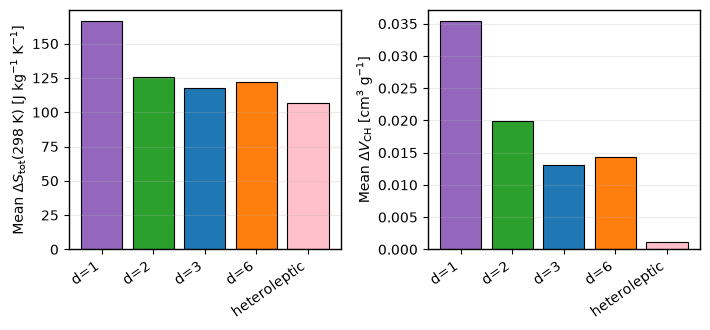

label,Mean dStotal [J mol-1 K-1],Mean dVCH [cm3 mol-1],N
d=1,106.35,23.89,12
d=2,75.39,13.46,50
d=3,72.34,7.53,207
d=6,60.10,6.89,30
heteroleptic,65.26,0.02,303


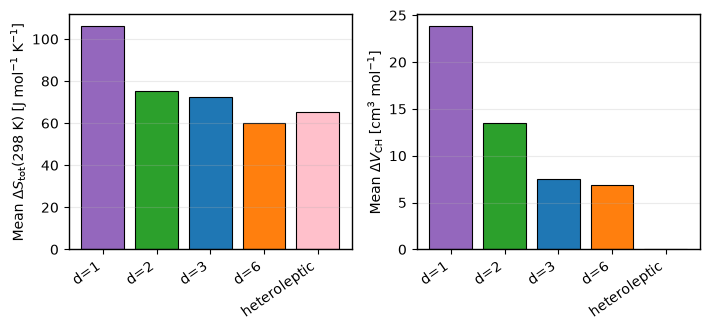

(<Figure size 720x340 with 2 Axes>,
 array([<Axes: ylabel='Mean $\\Delta S_{\\mathrm{tot}}(298\\ \\mathrm{K})$ [J mol$^{-1}$ K$^{-1}$]'>,
        <Axes: ylabel='Mean $\\Delta V_{\\mathrm{CH}}$ [cm$^3$ mol$^{-1}$]'>],
       dtype=object))

In [9]:
mass_summary = summarize_bce_by_denticity(
    screening_rows, mass_specific=True, denticities=denticities_to_compare
)
display_data_table(
    mass_summary, ['label', 'mean_entropy', 'mean_volume', 'num_entries'],
    labels={
        'mean_entropy': 'Mean dStotal [J kg-1 K-1]',
        'mean_volume': 'Mean dVCH [cm3 g-1]',
        'num_entries': 'N',
    },
)
plot_bce_denticity_averages(
    mass_summary,
    mass_specific=True,
    output_path=(figures_path + 'BCE_denticity_average_descriptors.png') if figures_path else None,
)

molar_summary = summarize_bce_by_denticity(
    screening_rows, mass_specific=False, denticities=denticities_to_compare
)
display_data_table(
    molar_summary, ['label', 'mean_entropy', 'mean_volume', 'num_entries'],
    labels={
        'mean_entropy': 'Mean dStotal [J mol-1 K-1]',
        'mean_volume': 'Mean dVCH [cm3 mol-1]',
        'num_entries': 'N',
    },
)
plot_bce_denticity_averages(
    molar_summary,
    mass_specific=False,
    output_path=(figures_path + 'BCE_denticity_average_descriptors_molar.png') if figures_path else None,
)

## 7. Interpretation

This analysis demonstrates reuse rather than a new computational workflow: thermodynamic and structural results generated elsewhere in the ATLAS are joined, normalized, filtered, and ranked without revisiting the underlying calculations. High-ranked systems are candidates for solid-state follow-up, where crystallographic volume changes, phonons, hysteresis, reversibility, and pressure response must be evaluated explicitly. Conversely, the GAPSIA benchmark shows that a modest molecular score cannot rule out strong BCE performance when the crystal environment amplifies the response.